## **X12**: TT - Richer readouts of the encoded state

#### **0° Introduction**

H-044 placed the loss of Module 7 in the **readout**: a QSVM on the fidelity kernel of C4 recovers 0.10–0.13 of test AUC over the MLP on the 12 values ⟨Zᵢ⟩, although both read the same encoded state |φ(x)⟩. This exploratory experiment measures three intermediate readouts of that same state, each fed to the **same MLP of Module 7** (D-036). The protocol was fixed before running (D-045):

| Arm | Representation | Columns | Extra measurements on hardware |
|---|---|---|---|
| **Z** (Z4, Z5) | 12 ⟨Zᵢ⟩ and 66 ⟨ZᵢZⱼ⟩ after the ansatz | 78 | none: the same bitstrings as C4 and C5 |
| **P** (P4, P5) | ⟨Xₖ⟩, ⟨Yₖ⟩, ⟨Zₖ⟩ of each qubit on the feature-map state, without ansatz | 36 (24 in P4) | three bases instead of one |
| **Q** (Q4, Q5) | 12 Kernel PCA components of the fidelity kernel, fitted on train like C3 | 12 | one circuit per pair of lesions |

Common input: the angles of Module 4, k = 12, c = 1, the feature maps of C4 and C5 and the θ of Module 5 (seed 42). Every value is exact, from the statevector.

Pre-registered comparisons: each arm against its origin (Z4 − C4, P4 − C4, Q4 − C4 and the C5 ones) and against C1, with the patient bootstrap of Module 7. The QSVM of X4 enters as a reference without being recomputed. **Declared prediction:** the three arms above C4 and C5 and below C1; Q limited by the nearly flat spectrum of the kernel.

This experiment was run after the report was delivered (3 Nov). It does not change the design or any existing number.

#### **1° Setup**

In [1]:
import copy
import json
import time
import warnings
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qiskit
import sklearn
import torch
from qiskit.circuit.library import pauli_feature_map, real_amplitudes, zz_feature_map
from qiskit.quantum_info import SparsePauliOp, Statevector
from scipy.stats import rankdata
from sklearn.decomposition import KernelPCA
from sklearn.metrics import accuracy_score, f1_score, pairwise_distances, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
torch.use_deterministic_algorithms(True)
torch.set_num_threads(1)
SEED, N_QUBITS, K = 42, 12, 12
FINDINGS = ['mass', 'calcification']
TITLES = {'mass': 'Masses', 'calcification': 'Calcifications'}
# protocol of Module 7 (D-036), unchanged
N_FOLDS, BATCH, MAX_EPOCHS, PATIENCE, INNER_VAL = 5, 128, 400, 40, 0.15
CONFIG = dict(hidden=(32, 16), lr=1e-3, weight_decay=1e-4, standardize=True)
N_BOOT = 2000
REPLICA = ['C1', 'C4', 'C5']
ARMS = ['Z4', 'P4', 'Q4', 'Z5', 'P5', 'Q5']
ORIGIN = {'Z4': 'C4', 'P4': 'C4', 'Q4': 'C4', 'Z5': 'C5', 'P5': 'C5', 'Q5': 'C5'}
ROOT = Path('/Users/alexander_san/TT')
M4_DIR, M5_DIR, M7_DIR = ROOT / 'Data/processed/m4', ROOT / 'Data/processed/m5', ROOT / 'Data/processed/m7'
RESULTS_DIR, FIG_DIR, OUT_DIR = ROOT / 'Code/results', ROOT / 'Docs/Figures', ROOT / 'Data/processed/x12'
OUT_DIR.mkdir(parents=True, exist_ok=True)
X_COLUMNS = [f'x_{i:02d}' for i in range(1, 13)]
COLORS = {'C1': '#eda100', 'C4': '#eb6834', 'C5': '#1baf7a'}
INK = '#3d3d3a'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.25, 'lines.linewidth': 2, 'lines.markersize': 8})
checks = []


def check(name, value, passed):
    checks.append({'check': name, 'value': float(value), 'passed': bool(passed)})
    print(f"{'PASS' if passed else 'FAIL'} | {name} | {value:.3g}")


print(f'qiskit {qiskit.__version__} | torch {torch.__version__} (CPU, deterministic) | scikit-learn {sklearn.__version__} | numpy {np.__version__}')

qiskit 2.3.0 | torch 2.10.0 (CPU, deterministic) | scikit-learn 1.7.2 | numpy 2.2.6


**b.** Load the angles of Module 4 and the representations of Module 5, and check that both list the same lesions in the same order

In [2]:
cols = lambda c, k=12: [f'{c}_{j:02d}' for j in range(1, k + 1)]
frames, angles = {}, {}
for ft in FINDINGS:
    m4 = pd.read_parquet(M4_DIR / f'x_{ft}.parquet')
    emb = pd.read_parquet(M5_DIR / f'emb_{ft}.parquet')
    same = m4.case_id.equals(emb.case_id) and m4.fold.equals(emb.fold) and m4.label.equals(emb.label)
    check(f'{ft}: Module 4 and Module 5 list the same lesions, folds and labels in the same order', 0, same)
    check(f'{ft}: C1 of Module 5 equals the angles of Module 4', np.abs(emb[cols('C1')].to_numpy() - m4[X_COLUMNS].to_numpy()).max(),
          np.array_equal(emb[cols('C1')].to_numpy(), m4[X_COLUMNS].to_numpy()))
    frames[ft], angles[ft] = emb, m4[X_COLUMNS].to_numpy(float)
    print(f"{ft}: {len(emb)} lesions, {int(emb.split.eq('train').sum())} train, {int(emb.split.eq('test').sum())} test")

PASS | mass: Module 4 and Module 5 list the same lesions, folds and labels in the same order | 0
PASS | mass: C1 of Module 5 equals the angles of Module 4 | 0
mass: 1696 lesions, 1318 train, 378 test
PASS | calcification: Module 4 and Module 5 list the same lesions, folds and labels in the same order | 0
PASS | calcification: C1 of Module 5 equals the angles of Module 4 | 0
calcification: 1872 lesions, 1546 train, 326 test


#### **2° The three readouts**

**a.** Statevectors. For each lesion and each feature map, two states: |φ(x)⟩ after the feature map alone (arms P and Q), and |ψ(x, θ)⟩ = W(θ)|φ(x)⟩ after the ansatz of Module 5 (arm Z). The circuit, the parameter binding and θ are those of `5a_Embeddings`, so the ⟨Zᵢ⟩ of arm Z must equal C4 and C5 exactly.

In [3]:
ansatz = real_amplitudes(N_QUBITS, reps=1)
theta = np.random.default_rng(SEED).uniform(0, 2 * np.pi, ansatz.num_parameters)
feature_maps = {'C4': zz_feature_map(N_QUBITS, reps=1), 'C5': pauli_feature_map(N_QUBITS, reps=1, paulis=['Y', 'ZZ'])}
meta5 = json.loads((M5_DIR / 'emb_meta.json').read_text())
check('theta equals the one saved by Module 5', np.abs(theta - np.array(meta5['theta'])).max(), np.array_equal(theta, np.array(meta5['theta'])))

basis = np.arange(2 ** N_QUBITS)[:, None]
signs = 1.0 - 2.0 * ((basis >> np.arange(N_QUBITS)) & 1)          # signs[b, i] = +1 if bit i of b is 0
PAIRS = list(combinations(range(N_QUBITS), 2))                      # 66 pairs, i < j
pair_signs = np.stack([signs[:, i] * signs[:, j] for i, j in PAIRS], axis=1)


def bind(circuit, fmap, x, with_theta):
    values = {p: float(v) for p, v in zip(fmap.parameters, x)}
    if with_theta:
        values.update({p: float(v) for p, v in zip(ansatz.parameters, theta)})
    return circuit.assign_parameters(values, inplace=False)


def states(fmap, x):
    # the feature-map statevectors (complex, n x 4096) and the probabilities after the ansatz (n x 4096)
    full = fmap.compose(ansatz)
    fm_states = np.empty((len(x), 2 ** N_QUBITS), complex)
    probs = np.empty((len(x), 2 ** N_QUBITS))
    for r, row in enumerate(x):
        fm_states[r] = Statevector.from_instruction(bind(fmap, fmap, row, False)).data
        probs[r] = Statevector.from_instruction(bind(full, fmap, row, True)).probabilities()
    return fm_states, probs


raw = {}
t0 = time.perf_counter()
for ft in FINDINGS:
    for name, fmap in feature_maps.items():
        raw[(ft, name)] = states(fmap, angles[ft])
print(f'statevectors of {sum(len(a) for a in angles.values())} lesions x 2 maps x 2 circuits in {time.perf_counter() - t0:.0f} s')

PASS | theta equals the one saved by Module 5 | 0


statevectors of 3568 lesions x 2 maps x 2 circuits in 102 s


**b.** Arm Z. Each shot in the Z basis returns the 12 bits at once; averaging one bit gives ⟨Zᵢ⟩ and averaging the product of two bits gives ⟨ZᵢZⱼ⟩. Exactly, both are linear in the probabilities.

In [4]:
def arm_z(probs):
    # <Z_i> row by row, the same vector-matrix product as 5a_Embeddings: a single matrix product
    # sums in another order and differs from Module 5 by ~1e-15 (first run of this notebook)
    return np.hstack([np.vstack([p @ signs for p in probs]), probs @ pair_signs])


Z_COLS = cols('Zi') + [f'ZZ_{i + 1:02d}_{j + 1:02d}' for i, j in PAIRS]

**c.** Arm P. For one qubit k, pair each basis state b with bit k = 0 with b + 2ᵏ, where the bit is 1. With a₀ and a₁ the two amplitudes, ⟨Xₖ⟩ = 2 Σ Re(a₀* a₁), ⟨Yₖ⟩ = 2 Σ Im(a₀* a₁) and ⟨Zₖ⟩ = Σ (|a₀|² − |a₁|²). These are the three coordinates of the Bloch vector of qubit k, the reduced state used by the projected kernel of X6 (§3.5.6).

In [5]:
def arm_p(fm_states):
    xs, ys = [], []
    for k in range(N_QUBITS):
        i0 = np.flatnonzero(((np.arange(2 ** N_QUBITS) >> k) & 1) == 0)
        w = (fm_states[:, i0].conj() * fm_states[:, i0 + 2 ** k]).sum(axis=1)
        xs.append(2 * w.real)
        ys.append(2 * w.imag)
    zs = np.abs(fm_states) ** 2 @ signs
    return np.hstack([np.stack(xs, 1), np.stack(ys, 1), zs])


P_COLS = cols('X') + cols('Y') + cols('Z')

**d.** Arm Q. The fidelity kernel K = |⟨φ(x)|φ(x′)⟩|² between every pair of lesions, from the statevectors (the exact shortcut of H-032), and a Kernel PCA with 12 components fitted on all of train and applied to every lesion, as C3 does with the RBF kernel in `5a_Embeddings`. The spectrum says how much of the centered kernel the 12 components keep; for reference, the same quantity for the RBF kernel of C3.

In [6]:
def median_gamma(x_train):
    sq = pairwise_distances(x_train, metric='sqeuclidean')
    return 1.0 / (2.0 * np.median(sq[np.triu_indices_from(sq, k=1)]))


def centered_share(K_train, n_comp=12):
    n = len(K_train)
    H = np.eye(n) - 1.0 / n
    ev = np.linalg.eigvalsh(H @ K_train @ H)[::-1]
    return ev[:n_comp].sum() / ev.sum(), ev


readouts, spectrum_rows, kernels = {}, [], {}
for ft in FINDINGS:
    tr = frames[ft].split.eq('train').to_numpy()
    gamma = median_gamma(angles[ft][tr])
    check(f'{ft}: the RBF bandwidth equals the one of Module 5 (D-027)', abs(gamma - meta5['gamma_by_finding_type'][ft]),
          abs(gamma - meta5['gamma_by_finding_type'][ft]) < 1e-12)
    K_rbf = np.exp(-gamma * pairwise_distances(angles[ft][tr], metric='sqeuclidean'))
    share_rbf, ev_rbf = centered_share(K_rbf)
    for name in feature_maps:
        fm_states, probs = raw[(ft, name)]
        K = np.abs(fm_states.conj() @ fm_states.T) ** 2
        kernels[(ft, name)] = K
        kpca = KernelPCA(n_components=12, kernel='precomputed').fit(K[np.ix_(tr, tr)])
        q = kpca.transform(K[:, tr])
        share_q, ev_q = centered_share(K[np.ix_(tr, tr)])
        off = K[np.ix_(tr, tr)][np.triu_indices(tr.sum(), k=1)]
        spectrum_rows.append({'finding_type': ft, 'kernel': f'fidelity {name}', 'n_train': int(tr.sum()), 'median_off_diagonal': np.median(off),
                              'share_top12_centered': share_q, 'effective_dimension': ev_q.sum() ** 2 / (ev_q ** 2).sum()})
        p = arm_p(fm_states)
        readouts[(ft, 'Z' + name[1])] = (arm_z(probs), Z_COLS)
        readouts[(ft, 'P' + name[1])] = (p, P_COLS)
        readouts[(ft, 'Q' + name[1])] = (q, cols('Q'))
    off = K_rbf[np.triu_indices(tr.sum(), k=1)]
    spectrum_rows.append({'finding_type': ft, 'kernel': 'RBF (C3)', 'n_train': int(tr.sum()), 'median_off_diagonal': np.median(off),
                          'share_top12_centered': share_rbf, 'effective_dimension': ev_rbf.sum() ** 2 / (ev_rbf ** 2).sum()})
spectrum = pd.DataFrame(spectrum_rows)
spectrum.to_csv(RESULTS_DIR / 'X12_espectro_kernel.csv', index=False)
display(spectrum.round(4))

PASS | mass: the RBF bandwidth equals the one of Module 5 (D-027) | 0


PASS | calcification: the RBF bandwidth equals the one of Module 5 (D-027) | 0


,finding_type,kernel,n_train,median_off_diagonal,share_top12_centered,effective_dimension
0,mass,fidelity C4,1318,0.0024,0.0237,1254.2759
1,mass,fidelity C5,1318,0.0000,0.0433,1048.4179
2,mass,RBF (C3),1318,0.6065,0.9244,4.5478
3,calcification,fidelity C4,1546,0.0027,0.0214,1466.5800
4,calcification,fidelity C5,1546,0.0000,0.0414,1129.2140
5,calcification,RBF (C3),1546,0.6065,0.9288,4.1329


**e.** Checks of the readouts

In [7]:
rng = np.random.default_rng(SEED)
for ft in FINDINGS:
    x = angles[ft]
    for name, fmap in feature_maps.items():
        a = name[1]
        z, _ = readouts[(ft, 'Z' + a)]
        p, _ = readouts[(ft, 'P' + a)]
        emb = frames[ft][cols(name)].to_numpy()
        check(f'{ft}: the <Z_i> of arm Z{a} equal {name} of Module 5', np.abs(z[:, :12] - emb).max(), np.array_equal(z[:, :12], emb))
        if a == '4':
            check(f'{ft}: in P4, <Z_k> = 0 for every lesion (H-013)', np.abs(p[:, 24:]).max(), np.abs(p[:, 24:]).max() < 1e-12)
        else:
            dev = np.abs(p[:, 24:] + np.sin(2 * x)).max()
            check(f'{ft}: in P5, <Z_k> = -sin(2 x_k)', dev, dev < 1e-12)
        bloch = np.sqrt(p[:, :12] ** 2 + p[:, 12:24] ** 2 + p[:, 24:] ** 2)
        check(f'{ft}: P{a} Bloch vectors have length <= 1', bloch.max() - 1, bloch.max() <= 1 + 1e-12)
        K = kernels[(ft, name)]
        check(f'{ft}: fidelity kernel {name} has unit diagonal and is symmetric', max(np.abs(np.diag(K) - 1).max(), np.abs(K - K.T).max()),
              np.abs(np.diag(K) - 1).max() < 1e-12 and np.abs(K - K.T).max() < 1e-12)
        dz = dp = 0.0
        for r in rng.choice(len(x), 5, replace=False):
            sv_full = Statevector.from_instruction(bind(fmap.compose(ansatz), fmap, x[r], True))
            sv_fm = Statevector.from_instruction(bind(fmap, fmap, x[r], False))
            ez = [np.real(sv_full.expectation_value(SparsePauliOp.from_sparse_list([('ZZ', [i, j], 1.0)], num_qubits=12)))
                  for i, j in PAIRS]
            dz = max(dz, np.abs(np.array(ez) - z[r, 12:]).max())
            ep = [np.real(sv_fm.expectation_value(SparsePauliOp.from_sparse_list([(P, [k], 1.0)], num_qubits=12)))
                  for P in 'XYZ' for k in range(12)]
            dp = max(dp, np.abs(np.array(ep) - p[r]).max())
        check(f'{ft}: Z{a} correlations match SparsePauliOp on 5 seeded lesions', dz, dz < 1e-12)
        check(f'{ft}: P{a} values match SparsePauliOp on 5 seeded lesions', dp, dp < 1e-12)

PASS | mass: the <Z_i> of arm Z4 equal C4 of Module 5 | 0
PASS | mass: in P4, <Z_k> = 0 for every lesion (H-013) | 1.86e-16
PASS | mass: P4 Bloch vectors have length <= 1 | -1.11e-16
PASS | mass: fidelity kernel C4 has unit diagonal and is symmetric | 1.44e-14
PASS | mass: Z4 correlations match SparsePauliOp on 5 seeded lesions | 6.8e-16
PASS | mass: P4 values match SparsePauliOp on 5 seeded lesions | 2.78e-16
PASS | mass: the <Z_i> of arm Z5 equal C5 of Module 5 | 0
PASS | mass: in P5, <Z_k> = -sin(2 x_k) | 8.88e-15
PASS | mass: P5 Bloch vectors have length <= 1 | -1.11e-16
PASS | mass: fidelity kernel C5 has unit diagonal and is symmetric | 1.8e-14
PASS | mass: Z5 correlations match SparsePauliOp on 5 seeded lesions | 2.05e-15
PASS | mass: P5 values match SparsePauliOp on 5 seeded lesions | 3.77e-15


PASS | calcification: the <Z_i> of arm Z4 equal C4 of Module 5 | 0
PASS | calcification: in P4, <Z_k> = 0 for every lesion (H-013) | 2.45e-16
PASS | calcification: P4 Bloch vectors have length <= 1 | -1.11e-16
PASS | calcification: fidelity kernel C4 has unit diagonal and is symmetric | 1.78e-14
PASS | calcification: Z4 correlations match SparsePauliOp on 5 seeded lesions | 6.11e-16
PASS | calcification: P4 values match SparsePauliOp on 5 seeded lesions | 9.44e-16
PASS | calcification: the <Z_i> of arm Z5 equal C5 of Module 5 | 0
PASS | calcification: in P5, <Z_k> = -sin(2 x_k) | 1.01e-14
PASS | calcification: P5 Bloch vectors have length <= 1 | -5.55e-16
PASS | calcification: fidelity kernel C5 has unit diagonal and is symmetric | 2.18e-14


PASS | calcification: Z5 correlations match SparsePauliOp on 5 seeded lesions | 7.77e-16
PASS | calcification: P5 values match SparsePauliOp on 5 seeded lesions | 6e-15


**f.** Drop the columns with zero variance on train, as fixed in D-045, and save the readouts

In [8]:
inputs = {}
for ft in FINDINGS:
    frame = frames[ft]
    tr = frame.split.eq('train').to_numpy()
    out = frame[['case_id', 'patient_id', 'split', 'label', 'fold']].copy()
    for cond in REPLICA:
        inputs[(ft, cond)] = frame[cols(cond)].to_numpy(float)
    for arm in ARMS:
        values, names = readouts[(ft, arm)]
        keep = values[tr].std(axis=0) > 1e-12
        inputs[(ft, arm)] = values[:, keep]
        print(f'{ft} {arm}: {keep.sum()} of {len(keep)} columns kept')
        out = pd.concat([out, pd.DataFrame(values, columns=[f'{arm}_{n}' for n in names])], axis=1)
    out.to_parquet(OUT_DIR / f'readouts_{ft}.parquet', index=False)
check('P4 keeps 24 columns in both subsets (the 12 <Z_k> are constant)', 0,
      all(inputs[(ft, 'P4')].shape[1] == 24 for ft in FINDINGS))

mass Z4: 78 of 78 columns kept
mass P4: 24 of 36 columns kept
mass Q4: 12 of 12 columns kept
mass Z5: 78 of 78 columns kept
mass P5: 36 of 36 columns kept
mass Q5: 12 of 12 columns kept
calcification Z4: 78 of 78 columns kept
calcification P4: 24 of 36 columns kept
calcification Q4: 12 of 12 columns kept
calcification Z5: 78 of 78 columns kept
calcification P5: 36 of 36 columns kept
calcification Q5: 12 of 12 columns kept
PASS | P4 keeps 24 columns in both subsets (the 12 <Z_k> are constant) | 0


#### **3° Classification with the MLP of Module 7**

The classifier, copied from `7_Classification` without changes (D-036): k → 32 → 16 → 1 with ReLU, weighted BCE, Adam with lr 10⁻³ and weight decay 10⁻⁴, batches of 128, early stopping with patience 40 on 15 % of the patients, standardization fitted on each training partition, seed 42. Cross-validation with the frozen folds of Module 4, then one fit on all of train evaluated once on test. C1, C4 and C5 are run again with the same code to check that it reproduces Module 7.

In [9]:
class MLP(torch.nn.Module):
    def __init__(self, n_in, hidden):
        super().__init__()
        layers, d = [], n_in
        for h in hidden:
            layers += [torch.nn.Linear(d, h), torch.nn.ReLU()]
            d = h
        layers.append(torch.nn.Linear(d, 1))
        self.net = torch.nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


def class_weights(y):
    n, n1 = len(y), int(y.sum())
    return {0: n / (2 * (n - n1)), 1: n / (2 * n1)}


def fit_predict(x_fit, y_fit, groups, x_eval, config, seed):
    inner_tr, inner_va = next(GroupShuffleSplit(n_splits=1, test_size=INNER_VAL, random_state=seed).split(x_fit, y_fit, groups))
    scaler = StandardScaler().fit(x_fit[inner_tr]) if config['standardize'] else None
    prep = (lambda a: torch.tensor(scaler.transform(a) if scaler else a, dtype=torch.float32))
    w = class_weights(y_fit[inner_tr])
    xt = prep(x_fit[inner_tr])
    yt = torch.tensor(y_fit[inner_tr], dtype=torch.float32)
    wt = torch.where(yt == 1, w[1], w[0])
    xv = prep(x_fit[inner_va])
    yv = torch.tensor(y_fit[inner_va], dtype=torch.float32)
    wv = torch.where(yv == 1, w[1], w[0])
    torch.manual_seed(seed)
    model = MLP(x_fit.shape[1], config['hidden'])
    opt = torch.optim.Adam(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
    loss_fn = torch.nn.BCEWithLogitsLoss(reduction='none')
    gen = torch.Generator().manual_seed(seed)
    best, best_state, best_epoch, wait = np.inf, None, 0, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        order = torch.randperm(len(xt), generator=gen)
        for i in range(0, len(xt), BATCH):
            b = order[i:i + BATCH]
            opt.zero_grad()
            (loss_fn(model(xt[b]), yt[b]) * wt[b]).mean().backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            val = float((loss_fn(model(xv), yv) * wv).mean())
        if val < best - 1e-6:
            best, best_state, best_epoch, wait = val, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(prep(x_eval))).numpy(), best_epoch


def metrics(y, p):
    yhat = (p >= 0.5).astype(int)
    return {'auc': roc_auc_score(y, p), 'f1': f1_score(y, yhat, zero_division=0), 'accuracy': accuracy_score(y, yhat),
            'precision': precision_score(y, yhat, zero_division=0), 'recall': recall_score(y, yhat, zero_division=0)}


def evaluate(ft, cond):
    frame = frames[ft]
    trm, tem = frame.split.eq('train').to_numpy(), frame.split.eq('test').to_numpy()
    tr, te = frame[trm], frame[tem]
    y, folds, groups = tr.label.to_numpy(int), tr.fold.to_numpy(int), tr.patient_id.to_numpy()
    x_all = inputs[(ft, cond)]
    x, x_te = x_all[trm], x_all[tem]
    rows, oof = [], np.empty(len(y))
    for f in range(N_FOLDS):
        fit, ev = folds != f, folds == f
        p, ep = fit_predict(x[fit], y[fit], groups[fit], x[ev], CONFIG, SEED)
        oof[ev] = p
        rows.append({'finding_type': ft, 'condition': cond, 'n_inputs': x.shape[1], 'fold': f, 'epochs': ep, **metrics(y[ev], p)})
    p_te, ep = fit_predict(x, y, groups, x_te, CONFIG, SEED)
    preds = [pd.DataFrame({'finding_type': ft, 'condition': cond, 'split': 'cv', 'case_id': tr.case_id, 'patient_id': tr.patient_id,
                           'label': y, 'fold': folds, 'prob': oof}),
             pd.DataFrame({'finding_type': ft, 'condition': cond, 'split': 'test', 'case_id': te.case_id, 'patient_id': te.patient_id,
                           'label': te.label.to_numpy(int), 'fold': -1, 'prob': p_te})]
    return rows, preds


cv_rows, pred_parts = [], []
t0 = time.perf_counter()
for ft in FINDINGS:
    for cond in REPLICA + ARMS:
        r, p = evaluate(ft, cond)
        cv_rows += r
        pred_parts += p
cv = pd.DataFrame(cv_rows)
preds = pd.concat(pred_parts, ignore_index=True)
print(f'{len(cv)} cross-validation fits and {len(REPLICA + ARMS) * len(FINDINGS)} test fits in {time.perf_counter() - t0:.0f} s')
cv.to_csv(RESULTS_DIR / 'X12_cv_por_fold.csv', index=False)
preds.to_parquet(OUT_DIR / 'predicciones.parquet', index=False)
display(cv.groupby(['finding_type', 'condition'], sort=False)[['n_inputs', 'auc', 'epochs']].agg(['mean', 'std']).round(3))

90 cross-validation fits and 18 test fits in 14 s


n_inputs         auc        epochs        
                            mean  std   mean    std   mean     std
finding_type  condition                                           
mass          C1            12.0  0.0  0.652  0.068   52.0  76.547
              C4            12.0  0.0  0.565  0.079    6.0   5.701
              C5            12.0  0.0  0.563  0.024   22.6  11.675
              Z4            78.0  0.0  0.586  0.051    6.8   1.789
              P4            24.0  0.0  0.568  0.046   16.8   5.541
              Q4            12.0  0.0  0.614  0.056   35.2  40.165
              Z5            78.0  0.0  0.611  0.043    7.4   4.159
              P5            36.0  0.0  0.624  0.072    9.0   5.477
              Q5            12.0  0.0  0.598  0.058   17.2  15.353
calcification C1            12.0  0.0  0.742  0.038   15.2  10.710
              C4            12.0  0.0  0.640  0.041   26.0  15.764
              C5            12.0  0.0  0.667  0.035   35.0   9.975
              Z4            78.0  0.0  0.683  0.043   10.0   2.550
              P4            24.0  0.0  0.689  0.020   38.4  19.655
              Q4            12.0  0.0  0.730  0.032   27.0  10.440
              Z5            78.0  0.0  0.697  0.021    7.2   0.837
              P5            36.0  0.0  0.719  0.028   19.8  12.276
              Q5            12.0  0.0  0.714  0.036   49.6  26.698

**b.** The replica of C1, C4 and C5 must reproduce Module 7: the AUC of every fold and every test prediction

In [10]:
cv7 = pd.read_csv(RESULTS_DIR / '7_cv_por_fold.csv')
cv7 = cv7[(cv7.analysis == 'main') & (cv7.config == 'base') & (cv7.seed == SEED)]
p7 = pd.read_parquet(M7_DIR / 'predicciones.parquet')
p7 = p7[(p7.analysis == 'main') & (p7.split == 'test')]
for ft in FINDINGS:
    for cond in REPLICA:
        a = cv[(cv.finding_type == ft) & (cv.condition == cond)].sort_values('fold').auc.to_numpy()
        b = cv7[(cv7.finding_type == ft) & (cv7.condition == cond)].sort_values('fold').auc.to_numpy()
        check(f'{ft}: {cond} reproduces the fold AUCs of Module 7', np.abs(a - b).max(), np.array_equal(a, b))
        mine = preds[(preds.finding_type == ft) & (preds.condition == cond) & (preds.split == 'test')].set_index('case_id').prob
        theirs = p7[(p7.finding_type == ft) & (p7.condition == cond)].set_index('case_id').prob.loc[mine.index]
        check(f'{ft}: {cond} reproduces the test predictions of Module 7', np.abs(mine.to_numpy() - theirs.to_numpy()).max(),
              np.array_equal(mine.to_numpy(), theirs.to_numpy()))
check('every fit stopped before the epoch limit', cv.epochs.max(), cv.epochs.max() < MAX_EPOCHS)

PASS | mass: C1 reproduces the fold AUCs of Module 7 | 0
PASS | mass: C1 reproduces the test predictions of Module 7 | 0
PASS | mass: C4 reproduces the fold AUCs of Module 7 | 0
PASS | mass: C4 reproduces the test predictions of Module 7 | 0
PASS | mass: C5 reproduces the fold AUCs of Module 7 | 0
PASS | mass: C5 reproduces the test predictions of Module 7 | 0
PASS | calcification: C1 reproduces the fold AUCs of Module 7 | 0
PASS | calcification: C1 reproduces the test predictions of Module 7 | 0
PASS | calcification: C4 reproduces the fold AUCs of Module 7 | 0
PASS | calcification: C4 reproduces the test predictions of Module 7 | 0
PASS | calcification: C5 reproduces the fold AUCs of Module 7 | 0
PASS | calcification: C5 reproduces the test predictions of Module 7 | 0
PASS | every fit stopped before the epoch limit | 184


**c.** Test metrics with the patient bootstrap of Module 7 (the same 2,000 resamples), and the pre-registered paired differences

In [11]:
def fast_auc(y, p):
    r = rankdata(p)
    n1 = y.sum()
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * (len(y) - n1))


def patient_bootstrap(test_frame, n_boot, seed):
    patients = test_frame.patient_id.to_numpy()
    uniq, inv = np.unique(patients, return_inverse=True)
    members = [np.flatnonzero(inv == i) for i in range(len(uniq))]
    rng = np.random.default_rng(seed)
    return [np.concatenate([members[i] for i in rng.integers(0, len(uniq), len(uniq))]) for _ in range(n_boot)]


test_rows, boot, point = [], {}, {}
for ft in FINDINGS:
    te = preds[(preds.finding_type == ft) & (preds.split == 'test')]
    ref = te[te.condition == 'C1'].reset_index(drop=True)
    samples = patient_bootstrap(ref, N_BOOT, SEED)
    for cond in REPLICA + ARMS:
        part = te[te.condition == cond].set_index('case_id').loc[ref.case_id]
        y, p = part.label.to_numpy(int), part.prob.to_numpy()
        dist = np.array([fast_auc(y[s], p[s]) for s in samples])
        boot[(ft, cond)], point[(ft, cond)] = dist, roc_auc_score(y, p)
        test_rows.append({'finding_type': ft, 'condition': cond, 'n_inputs': inputs[(ft, cond)].shape[1], **metrics(y, p),
                          'auc_ci_low': np.percentile(dist, 2.5), 'auc_ci_high': np.percentile(dist, 97.5)})
test = pd.DataFrame(test_rows)
test.to_csv(RESULTS_DIR / 'X12_test.csv', index=False)
t7 = pd.read_csv(RESULTS_DIR / '7_test.csv')
t7 = t7[t7.analysis == 'main'] if 'analysis' in t7 else t7
for ft in FINDINGS:
    for cond in REPLICA:
        mine = test[(test.finding_type == ft) & (test.condition == cond)].iloc[0]
        theirs = t7[(t7.finding_type == ft) & (t7.condition == cond)].iloc[0]
        dev = max(abs(mine.auc - theirs.auc), abs(mine.auc_ci_low - theirs.auc_ci_low), abs(mine.auc_ci_high - theirs.auc_ci_high))
        check(f'{ft}: {cond} test AUC and interval equal 7_test.csv', dev, dev < 1e-12)
display(test.round(3))

pairs = [(arm, ORIGIN[arm]) for arm in ARMS] + [(arm, 'C1') for arm in ARMS]
diff_rows = []
for ft in FINDINGS:
    for a, b in pairs:
        d = boot[(ft, a)] - boot[(ft, b)]
        lo, hi = np.percentile(d, [2.5, 97.5])
        diff_rows.append({'finding_type': ft, 'comparison': f'{a} - {b}', 'difference': point[(ft, a)] - point[(ft, b)],
                          'ci_low': lo, 'ci_high': hi, 'share_above_0': (d > 0).mean(),
                          'verdict': 'above' if lo > 0 else ('below' if hi < 0 else 'not significant')})
diffs = pd.DataFrame(diff_rows)
diffs.to_csv(RESULTS_DIR / 'X12_test_diferencias.csv', index=False)
display(diffs.round(3))

PASS | mass: C1 test AUC and interval equal 7_test.csv | 0
PASS | mass: C4 test AUC and interval equal 7_test.csv | 5.55e-17
PASS | mass: C5 test AUC and interval equal 7_test.csv | 0
PASS | calcification: C1 test AUC and interval equal 7_test.csv | 0
PASS | calcification: C4 test AUC and interval equal 7_test.csv | 0
PASS | calcification: C5 test AUC and interval equal 7_test.csv | 0


,finding_type,condition,n_inputs,auc,f1,accuracy,precision,recall,auc_ci_low,auc_ci_high
0,mass,C1,12,0.651,0.519,0.638,0.536,0.503,0.578,0.724
1,mass,C4,12,0.530,0.386,0.529,0.392,0.381,0.473,0.587
2,mass,C5,12,0.581,0.456,0.571,0.450,0.463,0.521,0.644
3,mass,Z4,78,0.553,0.406,0.590,0.465,0.361,0.485,0.619
4,mass,P4,24,0.556,0.402,0.606,0.490,0.340,0.487,0.628
5,mass,Q4,12,0.600,0.465,0.635,0.541,0.408,0.522,0.676
6,mass,Z5,78,0.581,0.472,0.598,0.482,0.463,0.507,0.657
7,mass,P5,36,0.621,0.521,0.611,0.500,0.544,0.549,0.696
8,mass,Q5,12,0.627,0.460,0.659,0.598,0.374,0.551,0.703
9,calcification,C1,12,0.769,0.665,0.666,0.551,0.837,0.694,0.836


,finding_type,comparison,difference,ci_low,ci_high,share_above_0,verdict
0,mass,Z4 - C4,0.023,-0.048,0.097,0.733,not significant
1,mass,P4 - C4,0.026,-0.044,0.100,0.758,not significant
2,mass,Q4 - C4,0.069,-0.004,0.149,0.966,not significant
3,mass,Z5 - C5,-0.000,-0.063,0.059,0.516,not significant
4,mass,P5 - C5,0.040,-0.029,0.114,0.880,not significant
5,mass,Q5 - C5,0.046,-0.028,0.117,0.914,not significant
6,mass,Z4 - C1,-0.097,-0.168,-0.031,0.002,below
7,mass,P4 - C1,-0.094,-0.165,-0.026,0.004,below
8,mass,Q4 - C1,-0.051,-0.086,-0.017,0.001,below
9,mass,Z5 - C1,-0.070,-0.125,-0.015,0.008,below


**d.** Figure: the ladder of readouts of the same state, from the 12 ⟨Zᵢ⟩ of Module 7 to the full kernel of X4, against C1

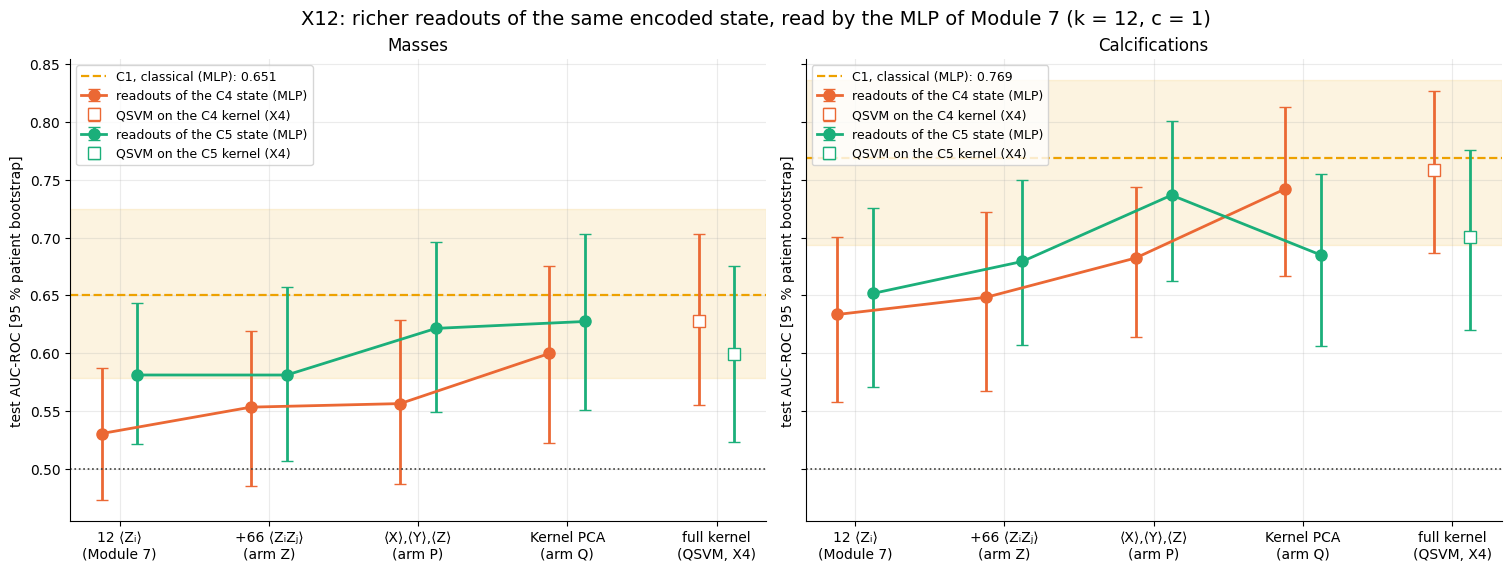

In [12]:
x4 = pd.read_csv(RESULTS_DIR / 'X4_test.csv')
LADDER = [('C{}', '12 ⟨Zᵢ⟩\n(Module 7)'), ('Z{}', '+66 ⟨ZᵢZⱼ⟩\n(arm Z)'), ('P{}', '⟨X⟩,⟨Y⟩,⟨Z⟩\n(arm P)'),
          ('Q{}', 'Kernel PCA\n(arm Q)'), ('QSVM', 'full kernel\n(QSVM, X4)')]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), constrained_layout=True, sharey=True)
for ax, ft in zip(axes, FINDINGS):
    c1 = test[(test.finding_type == ft) & (test.condition == 'C1')].iloc[0]
    ax.axhspan(c1.auc_ci_low, c1.auc_ci_high, color=COLORS['C1'], alpha=0.12)
    ax.axhline(c1.auc, color=COLORS['C1'], ls='--', lw=1.6, label=f'C1, classical (MLP): {c1.auc:.3f}')
    for off, a in [(-0.12, '4'), (0.12, '5')]:
        ys, lo, hi = [], [], []
        for template, _ in LADDER:
            if template == 'QSVM':
                r = x4[(x4.finding_type == ft) & (x4.model == f'QSVM C{a}, c = 1')].iloc[0]
            else:
                r = test[(test.finding_type == ft) & (test.condition == template.format(a))].iloc[0]
            ys.append(r.auc); lo.append(r.auc - r.auc_ci_low); hi.append(r.auc_ci_high - r.auc)
        pos = np.arange(len(LADDER)) + off
        color = COLORS[f'C{a}']
        ax.errorbar(pos[:-1], ys[:-1], yerr=[lo[:-1], hi[:-1]], fmt='o-', color=color, capsize=4, label=f'readouts of the C{a} state (MLP)')
        ax.errorbar(pos[-1:], ys[-1:], yerr=[lo[-1:], hi[-1:]], fmt='s', mfc='white', color=color, capsize=4,
                    label=f'QSVM on the C{a} kernel (X4)')
    ax.axhline(0.5, color=INK, ls=':', lw=1.2)
    ax.set_xticks(range(len(LADDER)), [lab for _, lab in LADDER])
    ax.set(title=TITLES[ft], ylabel='test AUC-ROC [95 % patient bootstrap]')
    ax.legend(fontsize=9, loc='upper left')
fig.suptitle('X12: richer readouts of the same encoded state, read by the MLP of Module 7 (k = 12, c = 1)', fontsize=14)
fig.savefig(FIG_DIR / 'X12_readouts.png', dpi=180, bbox_inches='tight')
plt.show()

#### **4° Verifications**

In [13]:
pd.DataFrame(checks).to_csv(RESULTS_DIR / 'X12_verificaciones.csv', index=False)
print(f"{sum(c['passed'] for c in checks)} of {len(checks)} checks passed")
display(pd.DataFrame(checks))

51 of 51 checks passed


,check,value,passed
0,mass: Module 4 and Module 5 list the same lesi...,0.000000e+00,True
1,mass: C1 of Module 5 equals the angles of Modu...,0.000000e+00,True
2,calcification: Module 4 and Module 5 list the ...,0.000000e+00,True
3,calcification: C1 of Module 5 equals the angle...,0.000000e+00,True
4,theta equals the one saved by Module 5,0.000000e+00,True
5,mass: the RBF bandwidth equals the one of Modu...,0.000000e+00,True
6,calcification: the RBF bandwidth equals the on...,0.000000e+00,True
7,mass: the <Z_i> of arm Z4 equal C4 of Module 5,0.000000e+00,True
8,"mass: in P4, <Z_k> = 0 for every lesion (H-013)",1.863744e-16,True
9,mass: P4 Bloch vectors have length <= 1,-1.110223e-16,True


#### **5° Reading** (H-058)

1. **For the C4 state, the more of the state a readout keeps, the more the MLP recovers.** Test AUC rises monotonically along the ladder in both subsets: 12 ⟨Zᵢ⟩ 0.530 → arm Z 0.553 → arm P 0.556 → arm Q 0.600 → full kernel 0.628 in masses, and 0.633 → 0.648 → 0.682 → 0.742 → 0.759 in calcifications.
2. **No readout reaches C1.** Every point estimate is below C1 (−0.023 to −0.120); 8 of the 12 arm − C1 differences are significantly negative and none is positive.
3. **The free correlations (arm Z) add little:** +0.000 to +0.028 over their origin, never significant. The line of §8.2 is measured and its gain is small.
4. **Only two gains over the origin are significant**, both in calcifications: Q4 − C4 = +0.109 [0.036, 0.182] and P5 − C5 = +0.085 [0.020, 0.151], out of 12 comparisons.
5. **The declared prediction about Q failed.** The 12 Kernel PCA components keep only 2–4 % of the centered kernel, against 92–93 % for the RBF of C3, yet Q4 is the best MLP readout of the C4 state in both subsets. The class information sits in a few directions of small variance.
6. **Caveat on P5.** Its ⟨Zₖ⟩ = −sin(2xₖ) is a classical function of each feature; part of its gain may come from those 12 columns rather than from the ZZ terms. Not tested here.